In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shlokbagwe/classification-train-test-df/test_df.parquet
/kaggle/input/datasets/shlokbagwe/classification-train-test-df/train_df.parquet


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
train_df = pd.read_parquet('/kaggle/input/datasets/shlokbagwe/classification-train-test-df/train_df.parquet')
test_df = pd.read_parquet('/kaggle/input/datasets/shlokbagwe/classification-train-test-df/test_df.parquet')

train_df_copy = train_df.copy()
test_df_copy = test_df.copy()

In [8]:
train_df.head()

,amount,use_chip,errors,abs_amount,target_numeric,gender,num_credit_cards,card_brand,card_type,has_chip,...,amount_zscore,mcc_fraud_rate,mcc_avg_amount,mcc_txn_count,city_fraud_rate,city_avg_amount,city_unique_customers,state_txn_count,client_fraud_rate,is_online
0,-77.00,Swipe Transaction,No Error,77.00,0.0,1,4,Mastercard,Debit (Prepaid),1,...,0.101336,0.000002,41.348915,807904,0.000000,68.709122,13,12388,0.003477,0
1,80.00,Swipe Transaction,No Error,80.00,0.0,0,3,Mastercard,Debit,1,...,0.459925,0.002286,90.184654,317560,0.000000,68.977081,40,773095,0.000629,0
2,14.57,Swipe Transaction,No Error,14.57,0.0,0,5,Mastercard,Credit,1,...,-0.380896,0.006168,56.963947,255855,0.000000,59.643684,16,86235,0.005267,0
3,46.41,Swipe Transaction,No Error,46.41,0.0,0,2,Visa,Debit,1,...,-0.413219,0.000599,25.170216,133609,0.001356,66.795120,5,104472,0.001960,0
4,4.81,Swipe Transaction,No Error,4.81,0.0,1,5,Mastercard,Debit (Prepaid),1,...,-0.599840,0.000353,19.289579,124678,0.000000,47.624516,169,464253,0.000749,0


Random Forest and XGBoost feature importance show how often and how effectively a feature was used while building the trees. A feature can receive a high importance simply because it is strongly related to another useful feature. Permutation importance measures how much the model actually depends on that feature for making predictions. Therefore, permutation importance was preferred when deciding which features

In [10]:
X_train = train_df.drop('target_numeric', axis=1)
y_train = train_df['target_numeric']

X_test = test_df.drop('target_numeric', axis=1)
y_test = test_df['target_numeric']

In [12]:
print( X_train.shape,"\n", y_train.shape, "\n", X_test.shape, "\n", y_test.shape)

(7194581, 30) 
 (7194581,) 
 (1798646, 30) 
 (1798646,)


In [14]:
X_train['errors'].value_counts()

errors
No Error                                 7077704
Insufficient Balance                       72565
Bad PIN                                    17654
Technical Glitch                           14553
Bad Card Number                             4256
Bad Expiration                              3346
Bad CVV                                     3345
Bad Zipcode                                  644
Other Error                                  222
Bad PIN,Insufficient Balance                 155
Insufficient Balance,Technical Glitch        137
Name: count, dtype: int64

In [15]:
keep_errors = ['Bad CVV', 'Bad PIN', 'Bad Card Number', 'Insufficient Balance', 'No Error']  # keeping only meaningful errors
X_train['errors'] = X_train['errors'].apply(lambda x: x if x in keep_errors else 'Other Error')
X_test['errors'] = X_test['errors'].apply(lambda x: x if x in keep_errors else 'Other Error')

In [16]:
drop_cols_round2 = [
    'client_fraud_rate', 'is_online', 'use_chip',
    'gender', 'has_chip', 'weekend_flag', 'num_cards_issued'
]

X_train = X_train.drop(columns=[c for c in drop_cols_round2 if c in X_train.columns])
X_test = X_test.drop(columns=[c for c in drop_cols_round2 if c in X_test.columns])

In [17]:
numerical_features = [
    'amount',
    'abs_amount',
    'debt_to_income',

    'hour',
    'day_of_week',

    'account_age_years',
    'years_since_pin_change',

    'txn_count_last_24h',
    'amount_sum_last_24h',

    'customer_avg_amount',
    'customer_txn_count',
    'amount_zscore',

    'mcc_fraud_rate',
    'mcc_avg_amount',
    'mcc_txn_count',

    'city_fraud_rate',
    'city_avg_amount',
    'city_unique_customers',

    'state_txn_count',

    'client_fraud_rate',

    'num_credit_cards',
    'num_cards_issued'
]
categorical_features = [
    'use_chip',
    'errors',
    'card_brand',
    'card_type'
]

In [18]:
numerical_features = [c for c in numerical_features if c not in drop_cols_round2]
categorical_features = [c for c in categorical_features if c not in drop_cols_round2]

In [19]:
numerical_features

['amount',
 'abs_amount',
 'debt_to_income',
 'hour',
 'day_of_week',
 'account_age_years',
 'years_since_pin_change',
 'txn_count_last_24h',
 'amount_sum_last_24h',
 'customer_avg_amount',
 'customer_txn_count',
 'amount_zscore',
 'mcc_fraud_rate',
 'mcc_avg_amount',
 'mcc_txn_count',
 'city_fraud_rate',
 'city_avg_amount',
 'city_unique_customers',
 'state_txn_count',
 'num_credit_cards']

In [20]:
categorical_features

['errors', 'card_brand', 'card_type']

In [28]:
print(set(X_train.columns) - set(numerical_features + categorical_features))
print(set(X_test.columns) - set(numerical_features + categorical_features))

set()


# Model Training

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier

In [25]:
numeric_transformer = Pipeline([('scaler', StandardScaler())])
categorical_transformer = Pipeline([('ohe', OneHotEncoder(handle_unknown='ignore'))])

In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [29]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('logistic', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000, verbose=1, n_jobs=-1))
])

baseline_pipeline.fit(X_train, y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg_amount',
                                                   'mcc_txn_count',
                                                   'city_fraud_rate',
                                                   'city_avg_amount',
                                                   'city_unique_customers',
                                                   'state_txn_count',
                                                   'num_credit_cards']),
                                                 ('cat',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['errors', 'card_brand',
                                                   'card_type'])])),
                ('logistic',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    n_jobs=-1, random_state=42, verbose=1))])

In [34]:
y_pred = baseline_pipeline.predict(X_test)
y_proba = baseline_pipeline.predict_proba(X_test)[:,1]

print("Accuracy: ",accuracy_score(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print("F1:", f1_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy:  0.898624298500094
PR-AUC: 0.24550416530409858
F1: 0.0330383042811915
              precision    recall  f1-score   support

         0.0       1.00      0.90      0.95   1795516
         1.0       0.02      1.00      0.03      3130

    accuracy                           0.90   1798646
   macro avg       0.51      0.95      0.49   1798646
weighted avg       1.00      0.90      0.94   1798646



In [39]:
pd.set_option('display.float_format', '{:,.0f}'.format)

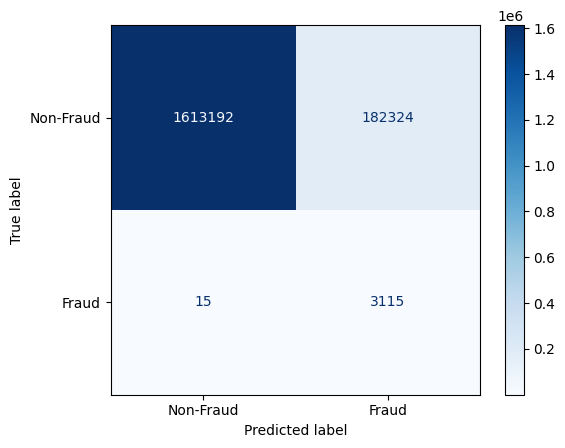

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

### Random Forest

In [17]:
# rf_pipeline = Pipeline([
#     ('preprocessor', preprocessor),
#     ('classifier', RandomForestClassifier(n_estimators=50, max_depth=8, n_jobs=-1, random_state=42, class_weight='balanced', verbose = 1))
# ])
# rf_pipeline.fit(X_train, y_train)

In [ ]:
# y_pred = rf_pipeline.predict(X_test)
# y_proba = rf_pipeline.predict_proba(X_test)[:,1]

# print("Accuracy: ",accuracy_score(y_test, y_pred))
# print("PR-AUC:", average_precision_score(y_test, y_proba))
# print("F1:", f1_score(y_test, y_pred))
# print(classification_report(y_test, y_pred))

In [15]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    scale_pos_weight=scale_pos_weight,
    max_depth=8,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=8, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [19]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: ",accuracy_score(y_test, y_pred_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy:  0.9817963067774315
PR-AUC: 0.18436417934177826
F1: 0.12799616490891658
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.07      0.77      0.13      3130

    accuracy                           0.98   1798646
   macro avg       0.53      0.87      0.56   1798646
weighted avg       1.00      0.98      0.99   1798646



In [20]:
y_train_prob = xgb_pipeline.predict_proba(X_train)[:,1]

print(average_precision_score(y_train,y_train_prob))

0.8193877189746737


In [21]:
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()


In [26]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    scale_pos_weight=200,
    max_depth=5,
    n_estimators=100,
    learning_rate=0.05,
    random_state=42,
    eval_metric='aucpr'
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [27]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: ",accuracy_score(y_test, y_pred_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy:  0.9768292371039103
PR-AUC: 0.1697504738548227
F1: 0.12131562302340292
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.06      0.92      0.12      3130

    accuracy                           0.98   1798646
   macro avg       0.53      0.95      0.55   1798646
weighted avg       1.00      0.98      0.99   1798646



In [28]:
y_train_prob = xgb_pipeline.predict_proba(X_train)[:,1]

print(average_precision_score(y_train,y_train_prob))

0.5921135790175536


In [33]:
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    tree_method='hist',

    n_estimators=300,
    learning_rate=0.05,

    max_depth=4,
    min_child_weight=10,

    subsample=0.8,
    colsample_bytree=0.8,

    gamma=1,

    reg_lambda=2,
    reg_alpha=0,

    scale_pos_weight=200,      # tune later
    eval_metric='aucpr',

    random_state=42
)

In [34]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy: ",accuracy_score(y_test, y_pred_xgb))
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy:  0.9768292371039103
PR-AUC: 0.1697504738548227
F1: 0.12131562302340292
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99   1795516
         1.0       0.06      0.92      0.12      3130

    accuracy                           0.98   1798646
   macro avg       0.53      0.95      0.55   1798646
weighted avg       1.00      0.98      0.99   1798646



In [42]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(y_test, y_proba_xgb)
print(f"\nROC AUC Score: {roc_auc:.4f}")


ROC AUC Score: 0.9909


In [43]:
import xgboost as xgb


xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    subsample=0.9,
    n_estimators=1000,
    max_depth=7,
    learning_rate=0.05,
    gamma=0.1,
    colsample_bytree=0.7,
    random_state=42
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=0.1, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=1000, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [44]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

PR-AUC: 0.49554561139839365
F1: 0.31825273010920435
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00   1795516
         1.0       0.85      0.20      0.32      3130

    accuracy                           1.00   1798646
   macro avg       0.93      0.60      0.66   1798646
weighted avg       1.00      1.00      1.00   1798646



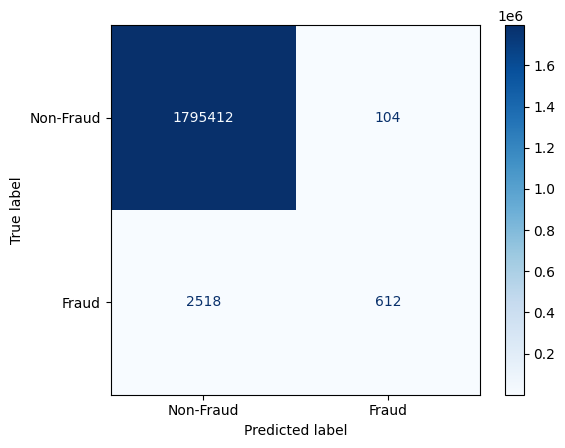

In [45]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()

In [47]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    tree_method='hist',
    subsample=0.9,
    n_estimators=500,
    max_depth=7,
    learning_rate=0.05,
    gamma=0.1,
    colsample_bytree=0.7,
    random_state=42,
    scale_pos_weight=scale_pos_weight
)

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['amount', 'abs_amount',
                                                   'debt_to_income', 'hour',
                                                   'day_of_week',
                                                   'account_age_years',
                                                   'years_since_pin_change',
                                                   'txn_count_last_24h',
                                                   'amount_sum_last_24h',
                                                   'customer_avg_amount',
                                                   'customer_txn_count',
                                                   'amount_zscore',
                                                   'mcc_fraud_rate',
                                                   'mcc_avg...
                               feature_types=None, feature_weights=None,
                               gamma=0.1, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=7, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=500, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [48]:
y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

PR-AUC: 0.26849055176103104
F1: 0.19053304904051171
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99   1795516
         1.0       0.11      0.71      0.19      3130

    accuracy                           0.99   1798646
   macro avg       0.55      0.85      0.59   1798646
weighted avg       1.00      0.99      0.99   1798646



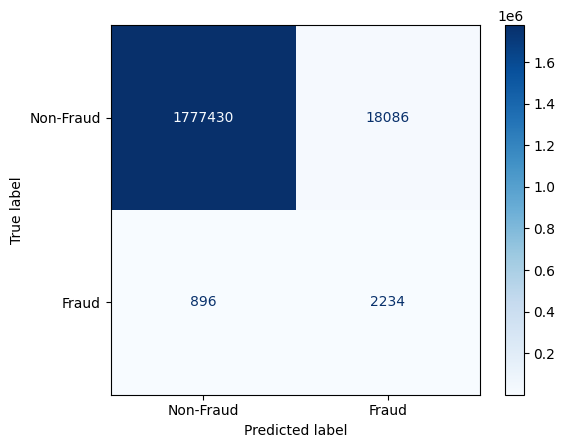

In [49]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    labels=[0,1],
    display_labels=['Non-Fraud', 'Fraud'], 
    cmap='Blues',
    values_format='d'
)

plt.show()